Following a set of vertices (first one automatically being current pos) with filtering in the background

For each vertex (except last)
1. Turn until within heading tol (i.e. facing next vertex). P(|theta-theta_0|>tol1) < eps1
2. Follow next line segment until within pos. tol. P(|x-v_i|>tol2) < eps2

## How to run
- **Kernel:** `.venv` in this folder (packages in `requirements.txt`). In VS Code: *Select Kernel → Python Environments → .venv*; in Jupyter: *BOMR Project (.venv)*.
- **Real Thymio:** connect the robot and open **Thymio Suite** (it runs the device manager that `tdmclient` talks to). Keep `USE_SIM = False`.
- **No robot:** set `USE_SIM = True` to run the same loop against a simulated Thymio.
- To stop, press the Thymio's **centre button** or interrupt the kernel. The motors are stopped either way. The last cell unlocks the robot.

Measurements are not in place yet, so only the motion model runs (`filtering.motion_model`, the EKF predict step). Its input is the measured wheel speeds, converted to `[v, omega]`. With no updates the covariance only grows.

**Frame:** mm, relative to the start pose. The origin is the wheel-axle midpoint, +x points the way the robot faces at start, +y is to its left, and theta is positive counter-clockwise.

Plotting lives in `plotting.py`, and the checks for the project modules are in `test_project.py`.

In [40]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import asyncio
import math
import time

import numpy as np

from control import LineSegment, follow_gain, turn_gain
from conversions import D, S, invtr_actuators, tr_actuators, wrap
from filtering import ProjectThymio, motion_model
from plotting import PathPlot, plot_timeseries, print_summary

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Parameters

In [41]:
USE_SIM = False          # True: simulated Thymio (no robot needed)
SIM_REALTIME = True      # sim only: run at real speed (False = as fast as possible)

# Vertices in mm, relative to the start pose. V0 = (0, 0), the start, is added automatically.
VERTICES = [(300, 0), (300, 200), (0, 0)]

TS = 0.1                 # control period [s]

# Phase 1: turn on the spot (turn_gain). The heading reference ramps from the current heading to
# the next segment's heading at W_RAMP, then stays constant. The tolerance is only checked once it
# has been constant for TURN_HOLD. With P control the robot lags the ramp by about W_RAMP / K_TURN rad.
K_TURN = 2.0             # [rad/s per rad]
W_RAMP = 0.8             # ramp rate of the heading reference [rad/s]
TURN_HOLD = 0.5          # time after the ramp ends before the tolerance is checked [s]
W_MAX = 1.2              # |omega| limit [rad/s]
W_MIN = 0.2              # minimum |omega| outside the tolerance, to get past the motor dead band [rad/s]
TOL_HEADING = np.deg2rad(3.0)

# Phase 2: follow the segment at one of two constant speeds (follow_gain gives omega):
#   cruise while the vertex is more than DOCK_DIST away, then dock until it's reached (no switching back).
# Each speed has its own gains, since the linearised cross-track dynamics (e' = v psi, psi' = omega)
# depend on v. The natural frequency is sqrt(k1 v), so k1 * v = const keeps the closed-loop poles.
DOCK_DIST = 70.0         # [mm]
V_CRUISE = 60.0          # [mm/s]
V_DOCK = 20.0            # [mm/s]
K_CRUISE = (0.02, 1.5)   # (k1 [rad/s per mm], k2 [rad/s per rad]) at V_CRUISE
K_DOCK = (0.06, 1.5)     # at V_DOCK: k1 scaled by V_CRUISE / V_DOCK, so the poles match cruise
TOL_POS = 10.0           # [mm]

SETTLE_TIME = 0.3        # pause with motors off between phases [s]
MAX_UNITS = 400          # motor target saturation [Thymio units]

# Decisions under uncertainty. With PROBABILISTIC = True they use the belief:
#   heading reached:  P(|theta - ref| > TOL_HEADING) < EPS_HEADING
#   vertex reached:   P(|x - v_i| > TOL_POS) < EPS_POS
#   cruise vs dock:   cruise while P(|x - v_i| > DOCK_DIST) >= P_CRUISE
# With False they use the mean instead (|mean error| < tol, |mean - v_i| > DOCK_DIST).
# With only the motion model, Sigma grows without bound, so keep this False until measurements are in.
PROBABILISTIC = False
EPS_HEADING = 0.05
EPS_POS = 0.05
P_CRUISE = 0.5

# Motion model (ProjectThymio). These are placeholders until calibrated, for v in mm/s and omega in rad/s:
#   var(v) = a1 v^2 + a2 omega^2,   var(omega) = a3 v^2 + a4 omega^2
ALPHAS = np.array([0.01, 25.0, 1e-6, 0.01])
Q0 = np.diag([0.01, 0.01, 1e-6])        # additive process noise per step [mm^2, mm^2, rad^2]
R = np.diag([1.0, 1.0, 1e-4])           # measurement noise (unused until measurements are added)
SIGMA0 = np.diag([1.0, 1.0, 1e-4])      # uncertainty of the start pose

VIZ_EVERY = 5            # redraw the live plot every N control steps

## Stopping rules and robot interfaces

In [42]:
_rng = np.random.default_rng(0)


def p_heading_outside(mu, sigma, theta_ref, tol):
    """P(|theta - theta_ref| > tol) under the Gaussian belief."""
    e = wrap(mu[2] - theta_ref)
    s = math.sqrt(max(sigma[2, 2], 1e-12))
    Phi = lambda z: 0.5 * (1 + math.erf(z / math.sqrt(2)))
    return 1.0 - (Phi((tol - e) / s) - Phi((-tol - e) / s))


def p_position_outside(mu, sigma, target, tol, n=4000):
    """P(|x - target| > tol) under the Gaussian belief (Monte Carlo)."""
    samples = _rng.multivariate_normal(mu[:2], sigma[:2, :2], n)
    return float(np.mean(np.linalg.norm(samples - target, axis=1) > tol))


def heading_reached(mu, sigma, theta_ref):
    if PROBABILISTIC:
        return p_heading_outside(mu, sigma, theta_ref, TOL_HEADING) < EPS_HEADING
    return abs(wrap(mu[2] - theta_ref)) < TOL_HEADING


def vertex_reached(mu, sigma, ls):
    if ls.progress(mu[:2]) >= ls.length:  # passed the vertex: stop rather than turn back
        return True
    if PROBABILISTIC:
        return p_position_outside(mu, sigma, ls.p2, TOL_POS) < EPS_POS
    return np.linalg.norm(mu[:2] - ls.p2) < TOL_POS


def cruise_allowed(mu, sigma, target):
    """True: cruise speed. False: close enough to the vertex to dock."""
    if PROBABILISTIC:
        return p_position_outside(mu, sigma, target, DOCK_DIST) >= P_CRUISE
    return np.linalg.norm(mu[:2] - target) > DOCK_DIST


def heading_ramp(theta_start, theta_goal, t):
    """Heading reference t seconds into the turn, and the ramp duration. The reference goes from
    theta_start to theta_goal (the short way round) at W_RAMP, then stays at theta_goal."""
    delta = wrap(theta_goal - theta_start)
    ref = wrap(theta_start + math.copysign(min(W_RAMP * t, abs(delta)), delta))
    return ref, abs(delta) / W_RAMP


def motors(left, right):
    return {"motor.left.target": [int(left)], "motor.right.target": [int(right)]}


class ThymioRobot:
    def __init__(self, client, node):
        self.client, self.node = client, node

    def now(self):
        return time.monotonic()

    def wheel_speeds(self):
        return np.array([self.node["motor.left.speed"], self.node["motor.right.speed"]], dtype=float)

    def set_wheel_speeds(self, left, right):
        self.node.send_set_variables(motors(left, right))

    async def sleep(self, dt):
        await self.client.sleep(dt)  # also processes incoming variable updates

    def abort_requested(self):
        return self.node["button.center"] == 1

    def stop(self):
        self.node.send_set_variables(motors(0, 0))

    def truth(self):
        return None


class SimRobot:
    """Differential-drive simulator. The wheels follow their targets with a first-order lag. Their
    true speed is slightly off from the reported one (scale_err), so dead reckoning drifts away from
    the truth the way it does on the real robot."""

    def __init__(self, realtime=True, noise=4.0, scale_err=(1.01, 0.99), tau=0.15, seed=1):
        self.realtime, self.noise, self.scale_err, self.tau = realtime, noise, np.array(scale_err), tau
        self.rng = np.random.default_rng(seed)
        self.t, self.pose = 0.0, np.zeros(3)
        self.target, self.actual = np.zeros(2), np.zeros(2)

    def now(self):
        return self.t

    def wheel_speeds(self):
        return np.round(self.actual + self.rng.normal(0, self.noise, 2))

    def set_wheel_speeds(self, left, right):
        self.target = np.array([left, right], dtype=float)

    async def sleep(self, dt):
        h = 0.005
        steps = max(1, round(dt / h))
        for _ in range(steps):
            self.actual += (self.target - self.actual) * (h / self.tau)
            vl, vr = S * self.actual * self.scale_err
            v, w = (vl + vr) / 2, (vr - vl) / D
            self.pose += np.array([v * h * np.cos(self.pose[2]), v * h * np.sin(self.pose[2]), w * h])
        self.t += steps * h
        await asyncio.sleep(steps * h if self.realtime else 0)

    def abort_requested(self):
        return False

    def stop(self):
        self.set_wheel_speeds(0, 0)

    def truth(self):
        return self.pose.copy()

## Control loop
For each vertex after V0:
1. **turn:** `turn_gain` tracks a heading reference that ramps at `W_RAMP` from the current heading to the direction of the vertex, then stays there. `heading_reached` is only checked once the reference has been constant for `TURN_HOLD`.
2. **cruise → dock:** `follow_gain` on `LineSegment(V_i, V_i+1)` gives omega. v is constant: `V_CRUISE` (gains `K_CRUISE`) while the vertex is more than `DOCK_DIST` away, then `V_DOCK` (gains `K_DOCK`) until `vertex_reached`, or until the vertex has been passed.

Between phases the motors pause for `SETTLE_TIME`. Each step: read the wheel speeds, run `motion_model`, compute `[v, omega]`, convert it with `tr_actuators`, and send it.


In [43]:
async def run(robot, vertices, viz=None):
    pt = ProjectThymio(TS, Q0, R, alphas=ALPHAS)
    mu, sigma = np.zeros(3), SIGMA0.copy()
    log, reached = [], []

    seg, phase, next_phase = 0, "turn", None
    theta_start, theta_goal, heading_ref, ls = None, None, 0.0, None
    t_start = t_prev = phase_t0 = robot.now()
    k, outcome = 0, "done"

    try:
        while seg < len(vertices) - 1:
            loop_t0 = robot.now()
            prev, target = np.asarray(vertices[seg], float), np.asarray(vertices[seg + 1], float)
            if np.linalg.norm(target - prev) < 1e-9:  # repeated vertex: nothing to do
                seg += 1
                continue

            # 1) predict: motion model with the measured wheel speeds as input
            u_meas = invtr_actuators(robot.wheel_speeds())
            now = robot.now()
            dt, t_prev = now - t_prev, now
            if dt > 0:
                pt.Ts = dt  # use the actual loop period
                mu, sigma = motion_model(mu, sigma, u_meas, pt)
                mu[2] = wrap(mu[2])

            # 2) phase logic and control
            u_cmd = np.zeros(2)
            if phase == "turn":
                if theta_goal is None:  # new turn: ramp from the current heading
                    theta_start = mu[2]
                    theta_goal = math.atan2(target[1] - mu[1], target[0] - mu[0])
                heading_ref, ramp_time = heading_ramp(theta_start, theta_goal, now - phase_t0)
                may_check = now - phase_t0 >= ramp_time + TURN_HOLD
                timed_out = now - phase_t0 > ramp_time + 15
                if (may_check and heading_reached(mu, sigma, heading_ref)) or timed_out:
                    if timed_out:
                        print(f"[warn] turn towards V{seg + 1} timed out")
                    phase, next_phase, phase_t0 = "settle", "cruise", now
                else:
                    omega = float(np.clip(turn_gain(mu, heading_ref, K_p=K_TURN)[1], -W_MAX, W_MAX))
                    if abs(wrap(heading_ref - mu[2])) > TOL_HEADING and abs(omega) < W_MIN:
                        omega = math.copysign(W_MIN, omega)
                    u_cmd = np.array([0.0, omega])
            elif phase in ("cruise", "dock"):
                if ls is None:
                    ls = LineSegment(prev, target)
                heading_ref = ls.theta
                timed_out = now - phase_t0 > 3 * ls.length / V_DOCK + 10
                if vertex_reached(mu, sigma, ls) or timed_out:
                    if timed_out:
                        print(f"[warn] segment to V{seg + 1} timed out")
                    phase, next_phase, phase_t0 = "settle", "next", now
                else:
                    if phase == "cruise" and not cruise_allowed(mu, sigma, target):
                        phase = "dock"  # stays docking until the vertex is reached
                    v, K = (V_CRUISE, K_CRUISE) if phase == "cruise" else (V_DOCK, K_DOCK)
                    omega = float(np.clip(follow_gain(mu, ls, K_p=K), -W_MAX, W_MAX))
                    u_cmd = np.array([v, omega])
            elif phase == "settle" and now - phase_t0 >= SETTLE_TIME:
                if next_phase == "next":
                    reached.append(dict(vertex=seg + 1, target=target, est=mu[:2].copy(), t=now - t_start,
                                        sd=np.sqrt(np.diag(sigma)[:2]), truth=robot.truth()))
                    seg, theta_goal, ls = seg + 1, None, None
                    phase, phase_t0 = "turn", now
                else:
                    phase, phase_t0 = next_phase, now

            # 3) actuate
            wheels = np.clip(np.round(tr_actuators(u_cmd)), -MAX_UNITS, MAX_UNITS)
            robot.set_wheel_speeds(*wheels)

            # 4) log and plot
            log.append(dict(t=now - t_start, mu=mu.copy(), sigma=sigma.copy(), u_meas=u_meas, u_cmd=u_cmd,
                            wheels=wheels, phase=phase, seg=seg, heading_ref=heading_ref, truth=robot.truth()))
            if viz is not None and k % VIZ_EVERY == 0 and seg < len(vertices) - 1:
                viz.update(mu, sigma, truth=robot.truth(), t=now - t_start, phase=phase,
                           target_idx=seg + 1, target=vertices[seg + 1],
                           heading_ref=heading_ref,
                           u_cmd=u_cmd, wheels=wheels)
            k += 1

            if robot.abort_requested():
                outcome = "aborted (centre button)"
                break
            await robot.sleep(max(0.005, TS - (robot.now() - loop_t0)))
    except (KeyboardInterrupt, asyncio.CancelledError):
        outcome = "interrupted"
    finally:
        robot.stop()

    if viz is not None:
        viz.finish(mu, sigma, outcome, truth=robot.truth())
    print_summary(outcome, log, reached)
    return log, reached

## Connect
This cell runs once. Rerunning it keeps the existing connection.

In [57]:
if USE_SIM:
    robot = SimRobot(realtime=SIM_REALTIME)
    print("Using the simulated Thymio")
else:
    if "node" not in globals():
        from tdmclient import ClientAsync
        client = ClientAsync()
        node = await client.wait_for_node()
        await node.lock()
    await node.wait_for_variables({"motor.left.speed", "motor.right.speed", "button.center"})
    robot = ThymioRobot(client, node)
    print("Connected to the Thymio and locked it")

vertices = [(0.0, 0.0)] + [tuple(map(float, v)) for v in VERTICES]
for i, (a, b) in enumerate(zip(vertices[:-1], vertices[1:])):
    print(f"V{i} ({a[0]:.0f}, {a[1]:.0f}) -> V{i + 1} ({b[0]:.0f}, {b[1]:.0f}): {math.dist(a, b):.0f} mm")

Connected to the Thymio and locked it
V0 (0, 0) -> V1 (300, 0): 300 mm
V1 (300, 0) -> V2 (300, 200): 200 mm
V2 (300, 200) -> V3 (0, 0): 361 mm


## Run
Put the robot down facing +x and run the cell. The plot updates live.

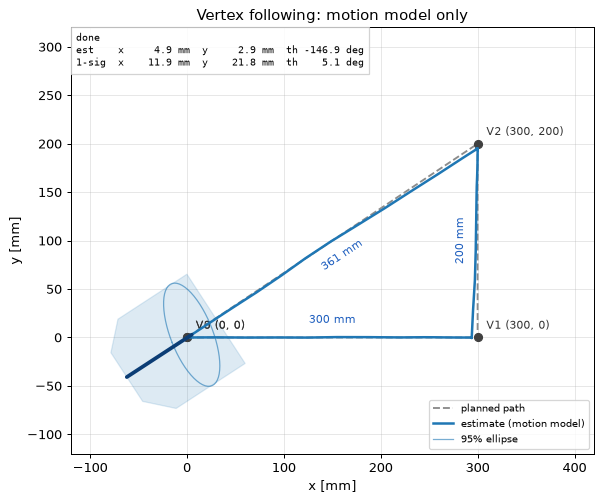

== done after 27.8 s ==
V1 (300, 0) at t =   8.0 s: est ( 293.9,   -0.0) mm, est. error  6.1 mm, 1-sigma (4.3, 8.1) mm
V2 (300, 200) at t =  16.2 s: est ( 300.0,  193.6) mm, est. error  6.4 mm, 1-sigma (12.3, 9.0) mm
V3 (0, 0) at t =  27.8 s: est (   4.9,    2.9) mm, est. error  5.6 mm, 1-sigma (11.9, 21.8) mm


In [58]:
viz = PathPlot(vertices, show_truth=USE_SIM)
viz.show()
log, reached = await run(robot, vertices, viz)

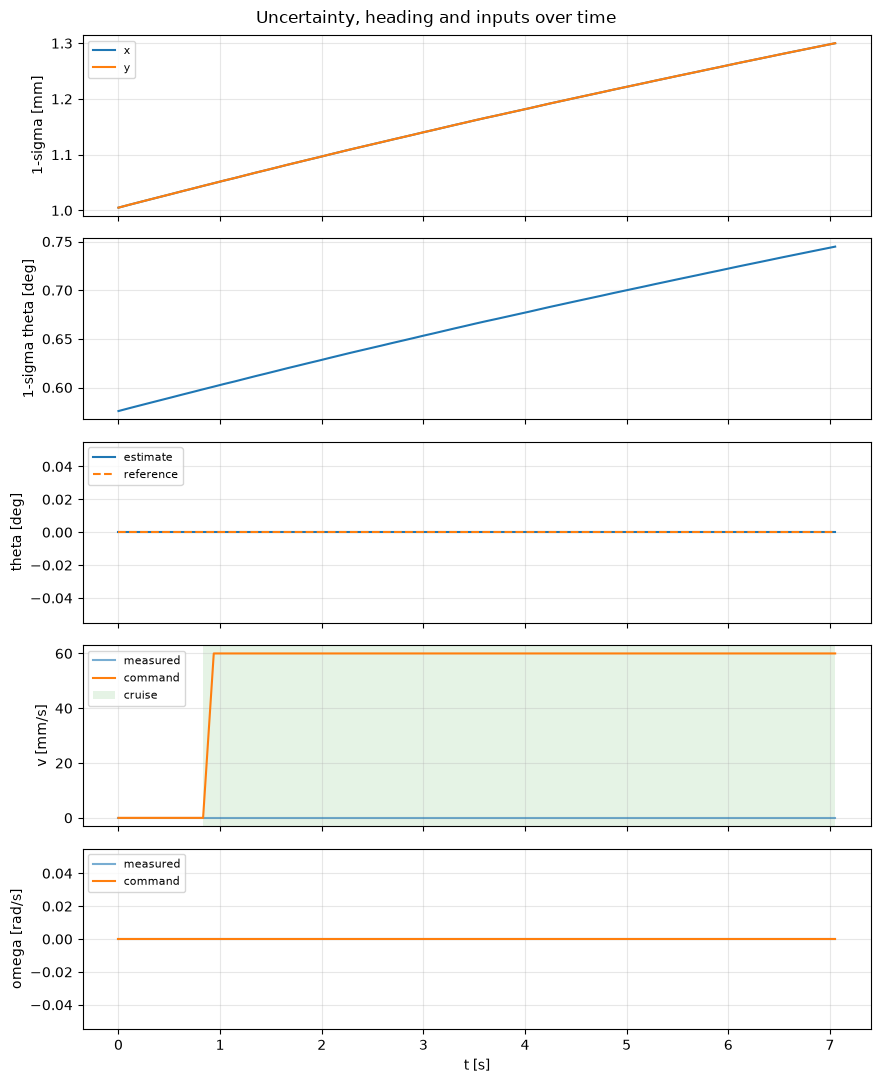

In [26]:
plot_timeseries(log, reached)

## Stop and unlock
This cell also works as an emergency stop.

In [56]:
robot.stop()
if not USE_SIM and "node" in globals():
    await node.set_variables(motors(0, 0))
    await node.unlock()
    del node
    print("Thymio stopped and unlocked")